# 05 · Prophet Forecasting

Additive/multiplicative seasonal model with automatic trend changepoints - a strong, interpretable baseline.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


In [2]:
series = daily.set_index("date")["units"].astype(float)
train, test = series.iloc[:-HOLDOUT_DAYS], series.iloc[-HOLDOUT_DAYS:]

## 1. Fit on the training window

In [3]:
from prophet import Prophet
from src.forecasting.ensemble import regression_metrics
df = pd.DataFrame({"ds": train.index, "y": train.values})
m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
            seasonality_mode="multiplicative", interval_width=0.90)
m.fit(df)
fc = m.predict(m.make_future_dataframe(periods=HOLDOUT_DAYS))
pred = fc.tail(HOLDOUT_DAYS)

## 2. Holdout accuracy

{'mae': 14.03, 'rmse': 18.108, 'wape': 0.11, 'bias': 3.08}


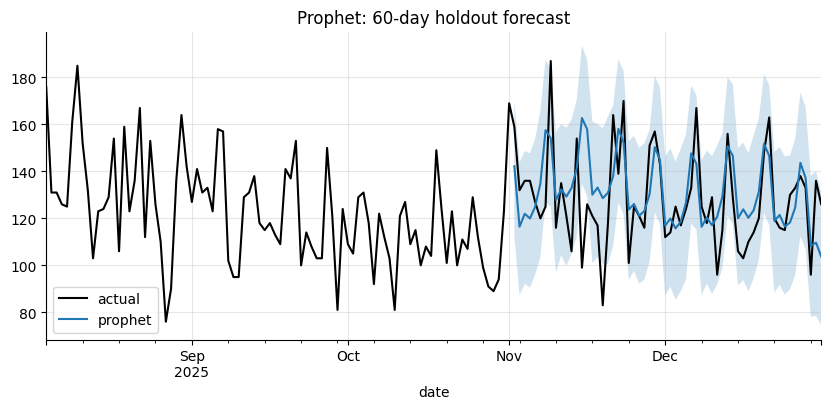

In [4]:
metrics = regression_metrics(test.values, pred["yhat"].clip(lower=0).values)
print({k: round(v, 3) for k, v in metrics.items()})
ax = series.tail(150).plot(label="actual", color="k")
ax.plot(pred["ds"], pred["yhat"], label="prophet", color="C0")
ax.fill_between(pred["ds"], pred["yhat_lower"], pred["yhat_upper"], alpha=.2)
plt.legend(); plt.title("Prophet: 60-day holdout forecast"); plt.show()

## 3. Interpretability - learned components

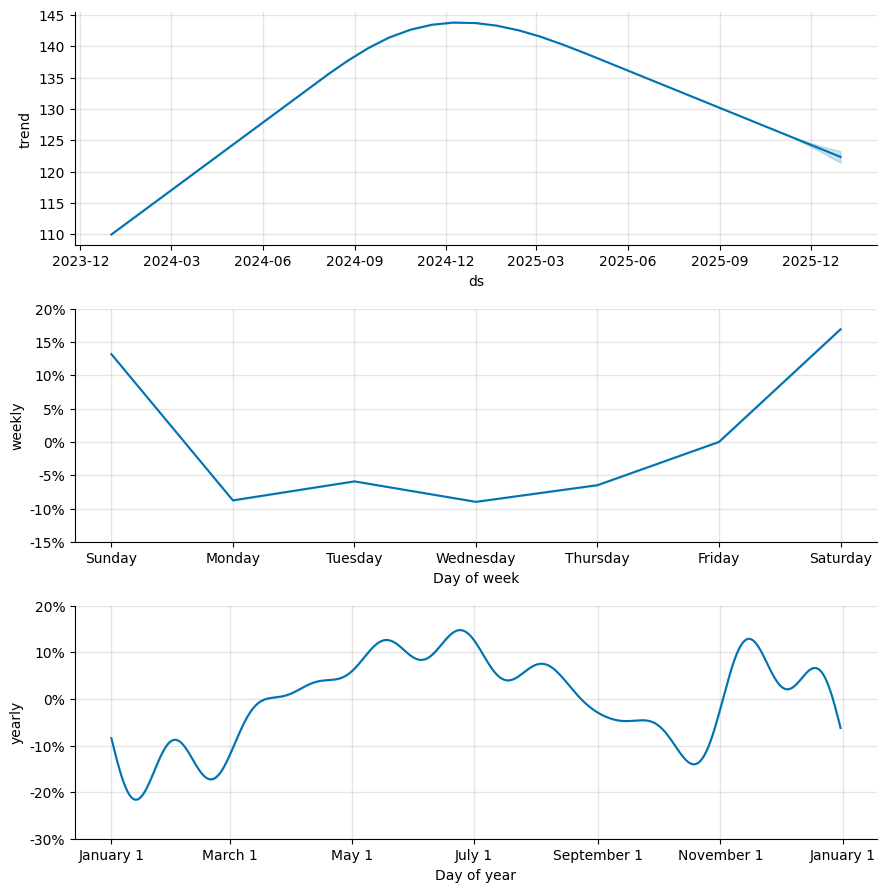

In [5]:
m.plot_components(fc); plt.show()

## 4. Same wrapper used by the pipeline

In [6]:
from src.forecasting.prophet_model import forecast_prophet
wrapped = forecast_prophet(train, HOLDOUT_DAYS)
print(round(regression_metrics(test.values, wrapped["yhat"].values)["mae"], 3), "MAE via src.forecasting.prophet_model")

14.03 MAE via src.forecasting.prophet_model
